# one-snapshot FK heat flux and submesoscale heat flux

In [23]:
# --------------------- your submesoscale heat flux (DO NOT MODIFY) -------------------
import xarray as xr

def vertical_heat_flux(
    ds_fine: xr.Dataset,
    ds_ocean: xr.Dataset,
    boundary_Z: str = "fill",
    to_wm2=True, 
):
    """
    compute the total heat flux
    """
    # merge the two dataset
    ds = xr.merge([ds_fine, ds_ocean])
    grid_fine = make_grid.make_grid_periodic_x(ds)
    # ---------- Build open interface area Aface (k_l,j,i) ----------
    # open_frac(k_l) = min(hFacC_k, hFacC_{k+1})
    upper = ds["hFacC"]                                  # (k,j,i)
    lower = ds["hFacC"].shift(k=-1, fill_value=0.0)      # (k+1,j,i)
    open_frac = xr.ufuncs.minimum(upper, lower).rename({'k': 'k_l'})  # (k_l,j,i)
    Aface = (open_frac * ds["RAC"]).astype('float32')                 # (k_l,j,i)
    # Valid interface mask (avoid coast/land)
    wet_w = Aface > 0

    # high resolution vertical heat flux
    # put T on W-interfaces
    T_w = grid_fine.interp(ds["T"], "Z", to="left", boundary=boundary_Z) # (k_l,j,i)
    print("W dims:", ds["W"].dims, ds["W"].shape)
    print("T dims:", ds["T"].dims, ds["T"].shape)
    print("T_w dims:", T_w.dims, T_w.shape)
    WT  = ds["W"] * T_w # (k_l,j,i)
    
    # Interpolate in vertical from k_l → k AFTER coarse-graining
    wT_kC = grid_fine.interp(WT, "Z", to="center",
                            boundary=boundary_Z).rename("wT_sub_kC")

    # ---------- Units: convert to W m^-2 if requested ----------
    if to_wm2:
        rho0, cp = 1035.0, 3994.0  # kg m^-3, J kg^-1 K^-1
        wT_kC = (rho0 * cp * wT_kC).assign_attrs(units="W m^-2")
    else:
        for da in (wT_sub_kL, wT_bar_kL, wT_sub_kC):
            da.attrs['units'] = "K m s^-1"

    # Some helpful long_names
    wT_kC.attrs['long_name'] = "heat flux"

    return wT_kC

# --------------------- module ----------------------------------
import os
from src.utils import make_grid
from src.utils import build_coarse_grid
from src.utils import read_mitgcm
import xarray as xr
import numpy as np
from src.utils import coarsen_UVWTS
from MITgcmutils import mds
from src.utils import mld_avg
import gsw
import importlib
importlib.reload(coarsen_UVWTS)   # force reload
# --------------------- submesoscale heat flux ----------------------------------
def submeso_vertical_heat_flux(
    ds_fine: xr.Dataset,
    ds_coarse: xr.Dataset,
    ds_ocean: xr.Dataset,
    ds_ocean_c: xr.Dataset,
    boundary_Z: str = "fill",
    box_j: int = 50,
    box_i: int = 50,
    to_wm2=True, 
):
    """
    Compute ⟨w'T'⟩ = ⟨wT⟩ − ⟨w⟩⟨T⟩ using 50x50 box averages (default).
    --------
    theta[k,j,i]: xarray.DataArray
        Potential temperature (K) on C-grid cell centers
    w[k,j,i]: xarray.DataArray
        Vertical velocity (m s^-1). If defined on vertical faces (k+1/2)
    hFacC[k,j,i]: 
        faction of the vertical thickness of the cell at level k, C means C-grid cell center
        1.0 - full wet, 
        0.0 - entirely land
        
    time_index: time point of variables
    box: spatial average box, km
    to_wm2: change the unit to wm2
    check_xarray: check if the data type is xarray
    
    Returns:
      wT_sub  : submesoscale vertical advective heat flux           (K·m s^-1, or W m^-2 if to_wm2=True)
      wT_bar  : coarse ⟨wT⟩                                         (same units)
      w_bar   : coarse ⟨w⟩                                          (m s^-1)
      T_bar   : coarse ⟨T⟩                                          (K)
    Notes:
      - Uses mask from hFacC; averages are NaN-skipping (equiv. to equal-area weighting on your uniform grid).
      - If W is on vertical faces (k+1/2), we interpolate T to those faces before forming wT.
    """
    # merge the two dataset
    ds = xr.merge([ds_fine, ds_ocean])
    grid_fine = make_grid.make_grid_periodic_x(ds)
    grid_coarse = make_grid.make_grid_periodic_x(ds_coarse)
    # ---------- Build open interface area Aface (k_l,j,i) ----------
    # open_frac(k_l) = min(hFacC_k, hFacC_{k+1})
    upper = ds["hFacC"]                                  # (k,j,i)
    lower = ds["hFacC"].shift(k=-1, fill_value=0.0)      # (k+1,j,i)
    open_frac = xr.ufuncs.minimum(upper, lower).rename({'k': 'k_l'})  # (k_l,j,i)
    Aface = (open_frac * ds["RAC"]).astype('float32')                 # (k_l,j,i)
    # Valid interface mask (avoid coast/land)
    wet_w = Aface > 0

    # high resolution vertical heat flux
    # put T on W-interfaces
    T_w = grid_fine.interp(ds["T"], "Z", to="left", boundary=boundary_Z) # (k_l,j,i)
    WT  = ds["W"] * T_w # (k_l,j,i)


    # ---------- Helper: area-weighted coarse mean on (j,i) ----------
    def _area_weighted_boxmean(A: xr.DataArray, WGT: xr.DataArray, box_j = 50, box_i=50 ) -> xr.DataArray:
        num = (A * WGT).coarsen(j=box_j, i=box_i, boundary="trim").sum()
        den = (WGT   ).coarsen(j=box_j, i=box_i, boundary="trim").sum()
        return xr.where(den > 0, num/den, np.nan)
    def as_ordinal(da: xr.DataArray) -> xr.DataArray:
        """Drop hitchhiking coords and replace each dim’s coordinate with 0..N-1."""
        da = da.reset_coords(drop=True)
        new_coords = {d: xr.DataArray(np.arange(da.sizes[d]), dims=d) for d in da.dims}
        return da.assign_coords(**new_coords)
    
    # ---------- Coarse means at k_l (interface placement) ----------
    wT_bar_kL = _area_weighted_boxmean(WT.where(wet_w),   Aface)
    w_bar_kL = (ds_ocean_c["W"])
    T_bar_kC = (ds_ocean_c["T"])
    T_bar_kL = grid_coarse.interp(T_bar_kC, "Z", to="left", boundary=boundary_Z) # (k_l,j,i))
    wT_bar_kL = as_ordinal(wT_bar_kL)
    
    # ---------- Submeso covariance at interfaces ----------
    wT_sub_kL = (wT_bar_kL - w_bar_kL * T_bar_kL).rename("wT_sub_kL")
    wT_bar_kL = wT_bar_kL.rename("wT_bar_kL")
    w_bar_kL  = w_bar_kL.rename("w_bar_kL")
    T_bar_kL  = T_bar_kL.rename("T_bar_kL")

    # ---------- Optional: move to centers in Z (for plotting/MLD averages) ----------
    # Interpolate in vertical from k_l → k AFTER coarse-graining
    wT_sub_kC = grid_coarse.interp(wT_sub_kL, "Z", to="center",
                            boundary=boundary_Z).rename("wT_sub_kC")
    wT_meso_kC = grid_coarse.interp(w_bar_kL * T_bar_kL, "Z", to="center",
                            boundary=boundary_Z).rename("wT_sub_kC")

    # Attach coarse coords from ds_grid if present
    if {'j','i'}.issubset(ds_coarse.coords):
        for da in (wT_sub_kL, wT_bar_kL, w_bar_kL, T_bar_kL, wT_sub_kC):
            # coarsen(...) already produced (j,i) reduced dims; enforce coarse coords
            if 'j' in da.dims: da = da.assign_coords(j=ds_coarse['j'])
            if 'i' in da.dims: da = da.assign_coords(i=ds_coarse['i'])
        # rebind names (xarray returns new objects when assign_coords)
        wT_sub_kL, wT_bar_kL, w_bar_kL, T_bar_kL, wT_sub_kC = [x for x in (wT_sub_kL,wT_bar_kL, w_bar_kL, T_bar_kL, wT_sub_kC)]

    # ---------- Units: convert to W m^-2 if requested ----------
    if to_wm2:
        rho0, cp = 1035.0, 3994.0  # kg m^-3, J kg^-1 K^-1
        wT_meso_kC = (rho0 * cp * wT_meso_kC).assign_attrs(units="W m^-2")
        wT_bar_kL = (rho0 * cp * wT_bar_kL).assign_attrs(units="W m^-2")
        wT_sub_kC = (rho0 * cp * wT_sub_kC).assign_attrs(units="W m^-2")
    else:
        for da in (wT_sub_kL, wT_bar_kL, wT_sub_kC):
            da.attrs['units'] = "K m s^-1"

    # Some helpful long_names
    wT_sub_kL.attrs['long_name'] = "submesoscale vertical heat flux at interfaces (area-weighted coarse)"
    wT_meso_kC.attrs['long_name'] = "coarse mean of wT at interfaces (area-weighted)"
    w_bar_kL.attrs['long_name']  = "coarse mean of w at interfaces (area-weighted)"
    T_bar_kL.attrs['long_name']  = "coarse mean of T (interp to interfaces) (area-weighted)"
    wT_sub_kC.attrs['long_name'] = "submesoscale vertical heat flux at centers (interp from interfaces)"

    return wT_meso_kC, wT_sub_kC


In [37]:
import numpy as np
import xarray as xr
from MITgcmutils import mds

def mean_12h_var_special(
    grid_dir: str,
    varname: str,
    start_time: int,
    dims: tuple[str, ...],
    *,
    ds_grid: xr.Dataset,
    snapshots_per_12h: int = 12,
    time_step: int = 180,
    diag_dir: str | None = None,
    field_index_kpphbl: int = 1,
):
    """
    Compute a 12-hour mean field from MITgcm outputs.

    Special cases:
      - varname == "Wstar_FK": compute from GM_diags
      - varname == "kpphbl":   load from DiagMXL_2d using mds.rdmds

    Parameters
    ----------
    grid_dir : str
        MITgcm run directory.
    varname : str
        Variable name.
    start_time : int
        Iteration of the first snapshot in the 12-hour averaging window.
    dims : tuple[str, ...]
        Dimensions for read_mitgcm._ocean_var, e.g. ("k_l","j","i").
        Ignored for special branches.
    ds_grid : xr.Dataset
        Grid dataset used to build xgcm grid and access metrics.
    snapshots_per_12h : int
        Number of snapshots to average. Default 12.
    time_step : int
        Iteration spacing between snapshots. Default 144.
    diag_dir : str | None
        Directory containing diagnostic files. If None, defaults to
        grid_dir + "Diags/".
    field_index_kpphbl : int
        Field index inside DiagMXL_2d for kpphbl. Default 1.

    Returns
    -------
    xr.DataArray
        12-hour mean field.
    """
    grid = make_grid.make_grid_periodic_x(ds_grid)

    if diag_dir is None:
        diag_dir = grid_dir + "Diags/"

    fields = []
    time_index = []

    for n in range(snapshots_per_12h):
        it = start_time + n * time_step

        if varname == "Wstar_FK":
            # -----------------------------------
            # special case 1: compute Wstar_FK
            # -----------------------------------
            GM_diags_FK = mds.rdmds(diag_dir + "GM_diags", it)

            psiX_FK = GM_diags_FK[0, ...]   # (k, j, i_g)
            psiY_FK = GM_diags_FK[1, ...]   # (k, j_g, i)

            psiX_FK = xr.DataArray(psiX_FK, dims=("k", "j", "i_g"))
            psiY_FK = xr.DataArray(psiY_FK, dims=("k", "j_g", "i"))

            dPsiY_dx_FK = (psiY_FK.roll(i=-1, roll_coords=False) - psiY_FK) / ds_grid["DXG"]
            dPsiX_dy_FK = (psiX_FK.shift(j=-1) - psiX_FK) / ds_grid["DYG"]

            dPsiY_dx_c_FK = grid.interp(dPsiY_dx_FK, "Y", boundary="fill")
            dPsiX_dy_c_FK = grid.interp(dPsiX_dy_FK, "X", boundary="periodic")

            da = (dPsiY_dx_c_FK - dPsiX_dy_c_FK).rename("Wstar_FK")

        elif varname == "kpphbl":
            # -----------------------------------
            # special case 2: load kpphbl from DiagMXL_2d
            # -----------------------------------
            diagMXL = mds.rdmds(diag_dir + "DiagMXL_2d", it)  # (nfields, j, i)
            da = xr.DataArray(
                diagMXL[field_index_kpphbl, :, :],
                dims=("j", "i"),
                name="kpphbl",
            )

        else:
            # -----------------------------------
            # default case: normal MITgcm variable
            # -----------------------------------
            da = read_mitgcm._ocean_var(grid_dir, varname, it, dims)
            da = da.drop_vars("time", errors="ignore")
            da.name = varname

        fields.append(da)
        time_index.append(it)

    out = xr.concat(
        fields,
        dim=xr.DataArray(time_index, dims="time", name="time")
    )

    out_mean = out.mean(dim="time", skipna=True)
    out_mean.name = varname
    out_mean.attrs["origin_iter"] = start_time
    out_mean.attrs["snapshots_used"] = snapshots_per_12h
    out_mean.attrs["time_step"] = time_step
    out_mean.attrs["mean_window"] = "12h"

    return out_mean

In [35]:
# load the w_bg, w_fk, T_bg
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))
from src.utils import make_grid
from src.utils import build_coarse_grid
from src.utils import read_mitgcm
import xarray as xr
import numpy as np
from src.utils import coarsen_UVWTS
from MITgcmutils import mds
from src.utils import mld_avg
import gsw

# --------------------- MITgcm folder path ----------------------------------
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_1km/verification/tutorial_reentrant_channel/output'
grid_dir = path_scratch + path_MITgcm

# --------------------- grid variable ----------------------------------
ds = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds,box_j=50, box_i=50)
start_time = 1245240

#----------------------------------------- background heat flux ----------------------------------
W_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="W",
    start_time=start_time,
    dims=("k_l", "j", "i"),
    ds_grid = ds
)
W_coarse = coarsen_UVWTS.coarse_field("W", W_12h, ds, box_j=50, box_i=50)
T_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="T",
    start_time=start_time,
    dims=("k", "j", "i"),
    ds_grid = ds
)
T_coarse = coarsen_UVWTS.coarse_field("T", T_12h, ds, box_j=50, box_i=50)
ds_ocean = xr.Dataset(dict(W=W_12h, T=T_12h))
print(T_coarse.shape)
ds_ocean_coarse = xr.Dataset(dict(W=W_coarse, T=T_coarse))

_, wT = submeso_vertical_heat_flux(ds, ds_coarse, ds_ocean, ds_ocean_coarse, box_j = 50, box_i = 50, boundary_Z = "fill", to_wm2 = True)

(49, 40, 20)


In [73]:
# now load the corresponding SubmesoFluxNet input variables
from src.utils import vel
from src.utils import strain
from src.utils import vorticity
from src.utils import mld_avg
from src.utils import make_grid
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_1km/verification/tutorial_reentrant_channel/output/'
grid_dir = path_scratch + path_MITgcm
# 
diagMXL = mds.rdmds(grid_dir + "Diags/" + "DiagMXL_2d", start_time)  # (nfields, j, i)
kpphbl_12h = xr.DataArray(
                diagMXL[1, :, :],
                dims=("j", "i"),
                name="kpphbl",
            )
kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl_12h, ds, box_j=50, box_i=50)
kpphbl_coarse = kpphbl_coarse.dropna(dim="j", how="all")
#  U, V, W, kpphbl, speed, strain, vorticity, and T
# load U and save the mld averaged U
U_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="U",
    start_time=start_time,
    dims=("k", "j", "i_g"),
    ds_grid = ds
)
U_coarse = coarsen_UVWTS.coarse_field("U", U_12h, ds, box_j=50, box_i=50)
# load V
V_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="V",
    start_time=start_time,
    dims=("k", "j_g", "i"),
    ds_grid = ds
)
V_coarse = coarsen_UVWTS.coarse_field("V", V_12h, ds, box_j=50, box_i=50)
# ds_ocean 
ds_ocean = xr.Dataset(dict(W=W_coarse, T=T_coarse, U=U_coarse, V=V_coarse))
# calculate the speed
boundary_Y = "fill"
speed_12h = vel._horizontal_speed(ds_coarse, ds_ocean, boundary_Y=boundary_Y)
strain_12h = strain._total_strain(ds_coarse, ds_ocean, boundary_Y=boundary_Y)
zeta_12h =  vorticity._vorticity(ds_coarse, ds_ocean, boundary_Y=boundary_Y)
# take mld_avg
grid = make_grid.make_grid_periodic_x(ds_coarse)
U_12h = grid.interp(U_coarse, "X", to="center", boundary="fill") # (k_l,j,i)
U_mld = mld_avg.mld_avg(U_12h[:,1:,:], kpphbl_coarse, ds_coarse)
V_12h = grid.interp(V_coarse, "Y", to="center", boundary="fill") # (k_l,j,i)
V_mld = mld_avg.mld_avg(V_12h[:,1:,:], kpphbl_coarse, ds_coarse)
W_12h = grid.interp(W_coarse, "Z", to="center", boundary="fill") # (k_l,j,i)
W_mld = mld_avg.mld_avg(W_12h[:,1:,:], kpphbl_coarse, ds_coarse)
T_mld = mld_avg.mld_avg(T_coarse[:,1:,:], kpphbl_coarse, ds_coarse)
kpphbl_mld = kpphbl_coarse
speed_mld = mld_avg.mld_avg(speed_12h[:,1:,:], kpphbl_coarse, ds_coarse)
strain_mld = mld_avg.mld_avg(strain_12h[:,1:,:], kpphbl_coarse, ds_coarse)
zeta_mld = mld_avg.mld_avg(zeta_12h[:,1:,:], kpphbl_coarse, ds_coarse)

In [74]:

nan_points = U_mld.where(U_mld.isnull(), drop=True)
print(nan_points)

<xarray.DataArray (j: 0, i: 0)> Size: 0B
array([], shape=(0, 0), dtype=float64)
Coordinates:
  * j        (j) int64 0B 
  * i        (i) int64 0B 
    k_p1     int64 8B 49


In [75]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

import numpy as np
import torch

from src.models.UNet_ConvLSTM_4En4De_pixel import UNetPhysDepth1


def load_unet_checkpoint(ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)

    # build model to match training
    model = UNetPhysDepth1(
        input_channels=8,
        head_channel=1,
        base=256,
        kernel_size=3,
        activation="SiLU",
        batch_norm="bn",
        dropout_2D=0.2,
        use_lstm=False,
        lstm_dropout=0.15,
    ).to(device)

    model.load_state_dict(ckpt["model"], strict=True)
    model.eval()

    norm = ckpt.get("norm", None)
    return model, norm


@torch.no_grad()
def predict_single_unet(model, X_single, device, X_mu=None, X_sd=None, y_mu=None, y_sd=None):
    """
    X_single: (C,H,W)
    returns y_pred: (1,1,H,W)
    """
    X_single = np.asarray(X_single, dtype=np.float32)

    if X_single.ndim != 3:
        raise ValueError(f"X_single must be (C,H,W), got {X_single.shape}")

    if X_mu is not None and X_sd is not None:
        X_single = (X_single - X_mu) / (X_sd + 1e-12)

    x = torch.from_numpy(X_single).unsqueeze(0).to(device)   # (1,C,H,W)
    y_pred = model(x).cpu().numpy()                          # (1,1,H,W)

    if y_mu is not None and y_sd is not None:
        y_pred = y_pred * (y_sd + 1e-12) + y_mu

    return y_pred

In [76]:
# ----------------------------
# example: build your 7-channel input
# all inputs should already be 2D with same shape, e.g. (56,56)
# ----------------------------
X_single = np.stack([
    np.asarray(U_mld),
    np.asarray(V_mld),
    np.asarray(W_mld),
    np.asarray(zeta_mld),
    np.asarray(strain_mld),
    np.asarray(T_mld),
    np.asarray(speed_mld),
    np.asarray(kpphbl_mld),
], axis=0)   # shape (7,H,W)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model, norm = load_unet_checkpoint(
    "/scratch/jczhang/submeso_data_driven/check_point/cfg_19/best_unet_conv.pt",
    device
)

X_mu = norm["X_mu"]
X_sd = norm["X_sd"]
y_mu = norm["y_mu"]
y_sd = norm["y_sd"]

y_pred = predict_single_unet(
    model,
    X_single,
    device,
    X_mu=X_mu,
    X_sd=X_sd,
    y_mu=y_mu,
    y_sd=y_sd,
)

print(y_pred.shape)   # (1,1,H,W)

pred_map = y_pred[0, 0]

(1, 1, 39, 20)


In [77]:
np.isnan(y_pred).any().item()

False

In [47]:
print(W_12h)

<xarray.DataArray (k: 49, j: 40, i: 20)> Size: 314kB
array([[[            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [ 9.01979036e-07,  8.53352339e-07,  6.52662426e-07, ...,
          7.85981041e-07,  8.62810882e-07,  1.01598653e-06],
        [ 3.42730893e-07,  2.16073160e-07,  2.60424847e-07, ...,
          2.82563385e-07,  2.65433749e-07,  3.28226977e-07],
        ...,
        [-8.98781968e-07,  3.27227545e-07,  1.49128218e-06, ...,
         -5.52140753e-07, -5.06023786e-07, -1.27675160e-07],
        [-3.34106011e-07, -4.18614084e-07, -5.76847694e-07, ...,
         -5.21935279e-07, -7.28706041e-08, -7.14858331e-07],
        [ 6.42745439e-07, -6.89700803e-07, -3.05486773e-07, ...,
          3.08008536e-07,  1.11157418e-08, -9.56081941e-07]],

       [[            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [ 2.47155325e-06,  2.28583561e-06,  1.6686

In [78]:
# calculate the fk and bg heat 

wT_bg_mld = mld_avg.mld_avg(wT, kpphbl_coarse, ds_coarse)

In [85]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

from src.utils import make_grid
from src.utils import build_coarse_grid 
from src.utils import read_mitgcm 
import xarray as xr 
import numpy as np 
import gsw 
import importlib 
from src.utils import coarsen_UVWTS 
from MITgcmutils import mds 
importlib.reload(coarsen_UVWTS) # force reload

def buo_coarse(
    ds_grid: xr.Dataset,
    ds_ocean: xr.Dataset,
    boundary_Y: str = "fill"
) -> xr.DataArray:

    # merge the two dataset
    ds = xr.merge([ds_grid, ds_ocean])
    grid = make_grid.make_grid_periodic_x(ds)
    # water collumn
    # Etabar: sea-surface height (j,i) [m]; broadcast add → z_c(k,j,i)
    z_rel = ds["RC"] - ds["Eta"]  # RC is negative, RC - Eta gives the depth of water column
    
    # TEOS10 EOS
    # model output is salinity and potential temperature
    # gsw function need absolute salinity and conservative temperature
    lat0, lon0 = -55.0, 153.0
    lat2d = xr.full_like(ds["T"].isel(k=0), lat0)               # (j,i)
    lon2d = xr.full_like(ds["T"].isel(k=0), np.mod(lon0, 360.)) # (j,i)

    # TEOS-10 sea pressure from depth (returns dbar)
    p_dbar = xr.apply_ufunc(
        gsw.p_from_z, z_rel, lat2d,
        dask="parallelized",
        output_dtypes=[ds["T"].dtype],
    )


    # --- convert SP, θ -> SA, CT -> ρ ---
    SA  = xr.apply_ufunc(gsw.SA_from_SP, ds["S"], p_dbar, lon2d, lat2d,
                         dask='parallelized', output_dtypes=[ds["S"].dtype])
    CT  = xr.apply_ufunc(gsw.CT_from_pt, SA, ds["T"],
                         dask='parallelized', output_dtypes=[ds["T"].dtype])
    rho = xr.apply_ufunc(gsw.rho, SA, CT, p_dbar,
                         dask='parallelized', output_dtypes=[ds["T"].dtype])  # kg m^-3
    # constants
    g = 9.81 # gravity
    rho0 = 1035 # density
    # buoyancy
    b = (-g * (rho - rho0) / rho0).where(ds["hFacC"] > 0)  # m s^-2
    b.name = "buoyancy"
    b.attrs.update(units="m s^-2", long_name="buoyancy (TEOS-10)")
    
    # ---- buoyancy gradient ----
    # Face wet masks (avoid bleeding across land/blocked faces)
    wetU = ds["hFacW"] > 0
    wetV = ds["hFacS"] > 0
    dbdx_u = (grid.diff(b, "X") / ds["DXC"]).where(wetU)                   # (k,j,i_g)
    dbdy_v = (grid.diff(b, "Y", boundary=boundary_Y) / ds["DYC"]).where(wetV)  # (k,j_g,i)
    return b, dbdx_u, dbdy_v

In [87]:
def _k_name(da): # Find the vertical dim name that matches your data 
    for cand in ("k", "Z", "z", "lev", "k_c"): 
        if cand in da.dims: 
            return cand 
            # fallback: assume first dim is vertical (adjust if needed) 
    return da.dims[0]

def mld_integrals_for_MEI( dbdx_u: xr.DataArray, # (k,j,i_g) ∂b/∂x at U 
                           dbdy_v: xr.DataArray, # (k,j_g,i) ∂b/∂y at V 
                           kpphbl_C: xr.DataArray, # (j,i) ML depth at C 
                           ds_grid: xr.Dataset, 
                           grid, 
                           sigma_is_buoyancy: bool = True, 
                           g: float = 9.81, 
                           rho0: float = 1035.0, 
                         ): 
    # ---- 0) Standardize the vertical index 'k' everywhere ---- 
    RF = ds_grid["RF"] # (k_p1), negative downward , 50
    K = RF.sizes["k_p1"] - 1  # 49
    k_index = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    ku = _k_name(dbdx_u) 
    kv = _k_name(dbdy_v) 
    dbdx_u = (dbdx_u.rename({ku: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    dbdy_v = (dbdy_v.rename({kv: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    # Mixed-layer depth at faces 
    H_C = kpphbl_C.clip(min=0.0) 
    H_U = grid.interp(H_C, "X", to="left") # (j,i_g) 
    H_V = grid.interp(H_C, "Y", to="left") # (j_g,i) 
    # ---- 1) Interfaces as positive-down depths with SAME 'k' coords ---- 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_index) # 0 to Nr -1
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_index) # 1 to Nr
    # Broadcast to faces (will use positional matching now that 'k' is unified) 
    ztop_U = ztop1d.broadcast_like(dbdx_u) # (k,j,i_g) 
    zbot_U = zbot1d.broadcast_like(dbdx_u) 
    ztop_V = ztop1d.broadcast_like(dbdy_v) # (k,j_g,i) 
    zbot_V = zbot1d.broadcast_like(dbdy_v) 
    # Partial-cell thickness on faces 
    thkU = (zbot_U - ztop_U) * ds_grid["hFacW"] 
    thkV = (zbot_V - ztop_V) * ds_grid["hFacS"] 
    # ---- 2) Overlap thickness with [0, H_face] (no xr.minimum) ---- 
    H3U = H_U.broadcast_like(dbdx_u) 
    H3V = H_V.broadcast_like(dbdy_v) 
    # min(H, zbot) = where(H <= zbot, H, zbot) 
    minHU = xr.where(H3U <= zbot_U, H3U, zbot_U) 
    minHV = xr.where(H3V <= zbot_V, H3V, zbot_V) 
    wU = xr.where(H3U > ztop_U, minHU - ztop_U, 0.0) 
    wV = xr.where(H3V > ztop_V, minHV - ztop_V, 0.0) 
    # clip and enforce partial thickness 
    wU = xr.where(wU > 0, xr.where(wU < thkU, wU, thkU), 0.0) 
    wV = xr.where(wV > 0, xr.where(wV < thkV, wV, thkV), 0.0) 
    # ---- 3) Integrals over 0..H (∑ sigma * dzLoc) ---- 
    intX = (dbdx_u.fillna(0.0) * wU).sum("k") # (j,i_g) 
    intY = (dbdy_v.fillna(0.0) * wV).sum("k") # (j_g,i) 
    # ---- 4) Convert if sigma are density-gradients (yours are buoyancy-gradients) ---- 
    if sigma_is_buoyancy: 
        dBuoyX_Hu, dBuoyY_Hv = intX, intY 
        out_units = "s^-2 m" 
    else: 
        fac = -g / rho0 
        dBuoyX_Hu, dBuoyY_Hv = fac * intX, fac * intY 
        out_units = "kg m^-4 s^-2" 
    # Optional: mask dry faces 
    wetU = (ds_grid["hFacW"] > 0).any("k") 
    wetV = (ds_grid["hFacS"] > 0).any("k") 
    dBuoyX_Hu = dBuoyX_Hu.where(wetU) 
    dBuoyY_Hv = dBuoyY_Hv.where(wetV) 
    dBuoyX_Hu.name, dBuoyY_Hv.name = "dBuoyX_Hu", "dBuoyY_Hv" 
    for da in (dBuoyX_Hu, dBuoyY_Hv): 
        da.attrs["long_name"] = "ML integral of horizontal buoyancy gradient" 
        da.attrs["units"] = out_units 
    return dBuoyX_Hu, dBuoyY_Hv

In [88]:
import numpy as np 
import xarray as xr 
def compute_Lf_MEI( dBuoyX_Hu: xr.DataArray, # (j, i_g) 
                    dBuoyY_Hv: xr.DataArray, # (j_g, i) 
                    b: xr.DataArray, # (k, j, i) buoyancy at C 
                    H_C: xr.DataArray, # (j, i) ML depth at C 
                    f_eff_C: xr.DataArray, # (j, i) 
                    ds_grid: xr.Dataset, 
                    grid, 
                    g: float = 9.81, 
                    rho0: float = 1035.0, 
                    LfMin: float = 1000.0, ): 
    # --- A) Standardize vertical coord 'k' everywhere ----------------------- 
    RF = ds_grid["RF"] # (k_p1) 
    K = RF.sizes["k_p1"] - 1 
    k_idx = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    def to_k(da): 
        # rename vertical dim to 'k' if needed, then assign common index 
        for cand in ("k", "Z", "z", "lev", "k_c"): 
            if cand in da.dims: 
                if cand != "k": 
                    da = da.rename({cand: "k"}) 
                break 
        if "k" in da.dims: 
                da = da.assign_coords(k=k_idx).reset_coords(drop=True) 
        return da 
    b = to_k(b) 
    hFacC = to_k(ds_grid["hFacC"]) # (k,j,i) with unified k 
    # (dBuoyX_Hu, dBuoyY_Hv, H_C, f_eff_C are 2D—no k to fix) 
    # interfaces as positive-down depths with SAME 'k' coords 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_idx) 
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_idx) 
    ztop = ztop1d.broadcast_like(b) 
    zbot = zbot1d.broadcast_like(b) 
    # --- 1) MsqH at centers from face integrals averaged to C --------------- 
    dBx_C = grid.interp(dBuoyX_Hu, 'X') # U->C 
    dBy_C = grid.interp(dBuoyY_Hv, 'Y') # V->C 
    MsqH = np.sqrt(0.25*(dBx_C**2 + dBy_C**2)) # s^-2 m 
    # --- 2) NHmixLay at C via ML overlap (honor partial cells) -------------- 
    thkC = (zbot - ztop) * hFacC # partial thickness 
    H3C = H_C.assign_coords().broadcast_like(b) # (k,j,i) with unified k 
    # min(H,zbot) without xr.minimum (avoids version issues) 
    minHC = xr.where(H3C <= zbot, H3C, zbot) 
    wC = xr.where(H3C > ztop, minHC - ztop, 0.0) 
    wC = xr.where(wC > 0, xr.where(wC < thkC, wC, thkC), 0.0) 
    # ∂b/∂z at C using interface spacing (downward-positive dz) 
    db = b - b.shift(k=1) 
    dz = (ztop - ztop.shift(k=1)) 
    sigmaR = (db / dz).where(dz.notnull()) 
    sigmaR_pos = xr.where(sigmaR < 0.0, -sigmaR, 0.0) 
    NH_term = (sigmaR_pos * wC).sum("k") # units: s^-2 * m 
    NHmixLay = np.sqrt(NH_term * H_C.clip(min=0.0)).fillna(0.0) 
    # --- 3) Lf at centers --------------------------------------------------- 
    fC = xr.where(f_eff_C > 0, f_eff_C, np.nan) 
    cand1 = MsqH / (fC**2) # m 
    cand2 = NHmixLay / fC # m 
    Lf_center = xr.ufuncs.maximum( xr.ufuncs.maximum(cand1.fillna(0.0), cand2.fillna(0.0)), LfMin ).rename("Lf") 
    Lf_center.attrs.update(long_name="MEI length scale at centers", units="m") 
    # --- 4) centers -> faces for streamfunction denominators ---------------- 
    Lf_U = grid.interp(Lf_center, 'X', to='left') # C->U 
    Lf_V = grid.interp(Lf_center, 'Y', to='left') # C->V 
    Lf_U.name, Lf_V.name = "Lf_U", "Lf_V" 
    return Lf_center, Lf_U, Lf_V

In [92]:
# modules 
from src.utils import read_mitgcm 
from src.utils import coarsen_UVWTS 
from src.utils import build_coarse_grid 
from src.utils import make_grid
import numpy as np 
import xarray as xr 
from MITgcmutils import mds 
from src.utils import mld_avg

# ---------------------------- parameters -------------------------------------
t = 1245240

box_i = box_j = 50 
# ---------------------------- MITgcm Path ------------------------------------- 
path_scratch = '/scratch/jczhang/' 
path_MITgcm = 'MITgcm_1km/verification/tutorial_reentrant_channel/output'
grid_dir = path_scratch + path_MITgcm 
# ---------------------------- grid ------------------------------------- 
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir) 
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i) 
grid = make_grid.make_grid_periodic_x(ds_coarse) 
# ---------------------------- Ce, ds ------------------------------------- 
# efficiency coefficient Ce 
C_e = 1.011
# hard upper cap - useless for my case, since dx < 111 km 
submeso_Lmax = 10000 # m 
# delta_s: local coarse model gridscale dimension 
delta_sx = ds_coarse["DXC"].clip(max=submeso_Lmax) # (j, i_g) 
delta_sy = ds_coarse["DYC"].clip(max=submeso_Lmax) # (j_g, i) 
# ---------------------------- mixed layer depth ------------------------------------ 
# mixed layer depth 
diagMXL = mds.rdmds(path_scratch + path_MITgcm + '/Diags/' +'DiagMXL_2d', t) 
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl") 
kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine, box_j, box_i) 
H_U = grid.interp(kpphbl_coarse, 'X', to='left') # (j, i_g) 
H_V = grid.interp(kpphbl_coarse, 'Y', to='left') # (j_g, i) 
# ---------------------------- buoyancy gradient and buoyancy ------------------------------------- 
T = read_mitgcm._ocean_var(grid_dir, "T", t, ("k","j","i")) 
T_coarse = coarsen_UVWTS.coarse_field("T", T, ds_fine, box_j, box_i) 
S = read_mitgcm._ocean_var(grid_dir, "S", t, ("k","j","i")) 
S_coarse = coarsen_UVWTS.coarse_field("S", S, ds_fine, box_j, box_i) 
Eta = read_mitgcm._ocean_var(grid_dir, "Eta", t, ("j","i")) 
Eta_coarse = coarsen_UVWTS.coarse_field("Eta", Eta, ds_fine, box_j, box_i) 
ds_ocean = xr.Dataset(dict(T=T, S=S, Eta=Eta)) 
ds_ocean_c = xr.Dataset(dict(T=T_coarse, S=S_coarse, Eta=Eta_coarse)) 
b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill") 
# integral over mixed layer 
dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI( dBdx_u, dBdy_V, kpphbl_coarse, ds_coarse, grid, sigma_is_buoyancy=True ) 
# ---------------------------- coriolis and tau------------------------------------- 
f0 = -1.363e-4 # s^-1 
beta = 1.313e-11 # s^-1 m^-1 
subMeso_invTau = 1.6e-6 
YC_da = xr.DataArray(ds_coarse["YC"], dims=('j','i')) 
y_ref = float(YC_da.mean()) 
f = (f0 + beta*(YC_da - y_ref)) # (j,i), s^-1 
f_eff = np.hypot(f, subMeso_invTau) 
f_U = grid.interp(f_eff, 'X', to='left') # (j,i_g) 
f_V = grid.interp(f_eff, 'Y', to='left') # (j_g,i) 
# ---------------------------- Lf = max(M/f, NH/|f|, Lf_min)------------------------------------- 
Lf_center, Lf_U, Lf_V = compute_Lf_MEI(dBuoyX_Hu=dBuoyX_Hu, dBuoyY_Hv=dBuoyY_Hv, b=b, H_C=kpphbl_coarse.clip(min=0.0), f_eff_C=f_eff, ds_grid=ds_coarse, grid=grid, LfMin=3600.0 ) 
# ---------------------------- mu(z)------------------------------------- 
# RF is negative downward (k_p1 interfaces); use it directly. 
rF = ds_coarse["RF"].rename(k_p1="k") # (k) ≤ 0 
rF_U = rF.broadcast_like(dBdx_u) # (k,j,i_g) 
rF_V = rF.broadcast_like(dBdy_V) # (k,j_g,i) 
# Mixed-layer depths on faces (positive) 
H_U = grid.interp(kpphbl_coarse.clip(min=0.0), 'X', to='left') 
H_V = grid.interp(kpphbl_coarse.clip(min=0.0), 'Y', to='left') 
# z2H must be negative inside the ML: [-2, 0] 
z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0) 
z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0) 
def mu_from(z2H): 
    q = (1.0 + z2H)**2 
    mu = (1.0 - q) * (1.0 + (5.0/21.0)*q) 
    return xr.where(mu > 0.0, mu, 0.0) 
muU = mu_from(z2H_U) # (k,j,i_g) 
muV = mu_from(z2H_V) # (k,j_g,i) 
# --- gridscale caps at faces (MIN(dx, Lmax), MIN(dy, Lmax)) --- 
dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax) # already (j, i_g) 
dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax) # already (j_g, i) 
# --- 2D streamfunction amplitudes at faces (depth-integrated) --- 
# bring the "other" horizontal component to the target face
dBuoyY_on_U = grid.interp(dBuoyY_Hv, 'Y')          # j_g,i -> j,i
dBuoyY_on_U = grid.interp(dBuoyY_on_U, 'X', to='left')

dBuoyX_on_V = grid.interp(dBuoyX_Hu, 'X')          # j,i_g -> j,i
dBuoyX_on_V = grid.interp(dBuoyX_on_V, 'Y', to='left')

PsiU0 = ( C_e * dBuoyY_on_U * H_U * dx_cap_U / (Lf_U * f_U) ).fillna(0.0)
PsiV0 = (-C_e * dBuoyX_on_V * H_V * dy_cap_V / (Lf_V * f_V) ).fillna(0.0)

# --- 3D streamfunctions using mu(z/H) --- 
muU_ = muU.transpose('k','j','i_g') # ensure consistent order for broadcasting 
muV_ = muV.transpose('k','j_g','i') 
PsiX = PsiU0.broadcast_like(muU_) * muU_ # (k,j,i_g) 
PsiY = PsiV0.broadcast_like(muV_) * muV_ # (k,j_g,i) 
PsiX.name, PsiY.name = "GM_PsiX_MEI", "GM_PsiY_MEI"

# --- grads of mean T on C, then to W (k,j,i) ---
wetU = ds_coarse["hFacW"] > 0
wetV = ds_coarse["hFacS"] > 0

dTdx_U = (grid.diff(T_coarse, 'X') / ds_coarse["DXC"]).where(wetU)      # (k,j,i_g)
dTdy_V = (grid.diff(T_coarse, 'Y', boundary='fill') / ds_coarse["DYC"]).where(wetV)  # (k,j_g,i)

# bring face-grads to centers
dTdx_C = grid.interp(dTdx_U.fillna(0.0), 'X')    # (k,j,i)
dTdy_C = grid.interp(dTdy_V.fillna(0.0), 'Y')    # (k,j,i)

# average C→W so vertical index matches Ψ(k,·,·) at W levels
dTdx_W = 0.5*(dTdx_C + dTdx_C.shift(k=1))
dTdy_W = 0.5*(dTdy_C + dTdy_C.shift(k=1))

# --- bring Ψ components to centers (same W levels) ---
PsiX_C = grid.interp(PsiX, 'X')    # (k,j,i)
PsiY_C = grid.interp(PsiY, 'Y')    # (k,j,i)

# --- vertical eddy temp flux from cross product ----------------------------
Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")   # (k,j,i)
Fz_T_cross.attrs.update(long_name="(Ψ × ∇T)_z", units="K m s^-1?  see note")

# (optional) convert to heat units
rho0, cp = 1035.0, 3990.0
Qz_T_cross = (rho0 * cp) * Fz_T_cross

Qz_T_cross.name = "Qz_T_cross"
Qz_T_cross.attrs.update(units="W m^-2")
submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl_coarse, ds_coarse)
# 
dbdx_C = grid.interp(dBdx_u.fillna(0.0), 'X')
dbdy_C = grid.interp(dBdy_V.fillna(0.0), 'Y')

dbdx_W = 0.5 * (dbdx_C + dbdx_C.shift(k=1))
dbdy_W = 0.5 * (dbdy_C + dbdy_C.shift(k=1))

Fz_b = (PsiX_C * dbdy_W - PsiY_C * dbdx_W).rename("Fz_b")
Fz_b_ml = mld_avg.mld_avg(Fz_b, kpphbl_coarse, ds_coarse)

In [110]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cmocean.cm as cmo

def sym_limit(*arrays, q=0.995):
    vals = []
    for a in arrays:
        a = np.asarray(a)
        vals.append(np.abs(a[np.isfinite(a)]).ravel())
    vals = np.concatenate(vals)
    return float(np.nanquantile(vals, q))

def plot_three_flux_maps(pred, fk, background, q=0.995, savepath=None):
    pred = np.asarray(pred)
    fk = np.asarray(fk)
    background = np.asarray(background)

    if pred.shape != (20, 20):
        raise ValueError(f"pred shape is {pred.shape}, expected (56, 56)")
    if fk.shape != (20, 20):
        raise ValueError(f"fk shape is {fk.shape}, expected (56, 56)")
    if background.shape != (20, 20):
        raise ValueError(f"background shape is {background.shape}, expected (56, 56)")

    clim = sym_limit(pred, fk, background, q=q)
    norm = TwoSlopeNorm(vcenter=0.0, vmin=-clim, vmax=clim)

    fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), constrained_layout=True)

    im0 = axes[0].imshow(pred, origin="lower", cmap=cmo.balance, norm=norm)
    axes[0].set_title("SubmesoFluxNet", fontsize=13)

    im1 = axes[1].imshow(fk, origin="lower", cmap=cmo.balance, norm=norm)
    axes[1].set_title("Fox-Kemper", fontsize=13)

    im2 = axes[2].imshow(background, origin="lower", cmap=cmo.balance, norm=norm)
    axes[2].set_title("Truth", fontsize=13)

    panel_labels = ["(a)", "(b)", "(c)"]
    for ax, lab in zip(axes, panel_labels):
        ax.text(
            0.02, 0.98, lab,
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=13, fontweight="bold"
        )
        ax.set_xticks([])
        ax.set_yticks([])

    cbar = fig.colorbar(im2, ax=axes, shrink=0.9, pad=0.03)
    cbar.set_label(r"Heat flux [$\mathrm{W\,m^{-2}}$]", fontsize=12)

    if savepath is not None:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")

    plt.show()

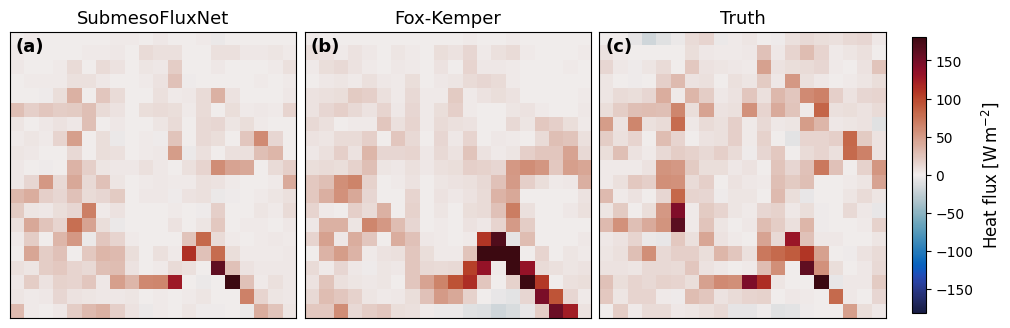

In [111]:
plot_three_flux_maps(
    pred=y_pred[0,0,19:,:],
    fk=submeso_wT_FK[20:,:],
    background=wT_bg_mld[20:,:],
    savepath="pred_fk_background.png",
)


In [96]:
import numpy as np

def r2_score_2d(y_true, y_pred):
    yt = np.asarray(y_true, dtype=np.float64)
    yp = np.asarray(y_pred, dtype=np.float64)

    if yt.shape != yp.shape:
        raise ValueError(f"Shape mismatch: {yt.shape} vs {yp.shape}")

    mask = np.isfinite(yt) & np.isfinite(yp)
    yt = yt[mask]
    yp = yp[mask]

    sse = np.sum((yp - yt) ** 2)
    sst = np.sum((yt - np.mean(yt)) ** 2)

    if sst == 0:
        return np.nan

    return 1.0 - sse / sst

In [97]:
r2_pred_vs_background = r2_score_2d(wT_bg_mld[1:,:], y_pred[0,0,:,:])
r2_fk_vs_background = r2_score_2d(wT_bg_mld[1:,:], submeso_wT_FK[1:,:])

print("R2(pred, background) =", r2_pred_vs_background)
print("R2(fk, background)   =", r2_fk_vs_background)

R2(pred, background) = 0.5327873565878003
R2(fk, background)   = 0.018057903241009976
